In [ ]:
!pip install -q transformers datasets torchaudio librosa scikit-learn seaborn

from google.colab import drive
drive.mount('/content/drive')

import os
import torch
import librosa
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from datasets import Dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

from transformers import (
    Wav2Vec2Processor,
    Wav2Vec2ForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
    EarlyStoppingCallback
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using device: cuda


In [ ]:
DATASET_PATH = "/content/drive/MyDrive/Datasets/IESC_Hindi"

data = []

for speaker in os.listdir(DATASET_PATH):
    speaker_path = os.path.join(DATASET_PATH, speaker)
    if not os.path.isdir(speaker_path):
        continue

    for session in os.listdir(speaker_path):
        session_path = os.path.join(speaker_path, session)
        if not os.path.isdir(session_path):
            continue

        for emotion in os.listdir(session_path):
            emotion_path = os.path.join(session_path, emotion)
            if not os.path.isdir(emotion_path):
                continue

            for file in os.listdir(emotion_path):
                if file.endswith(".wav"):
                    data.append({
                        "speaker": speaker,
                        "emotion": emotion.lower(),
                        "path": os.path.join(emotion_path, file)
                    })

df = pd.DataFrame(data)

print("Total samples:", len(df))
print(df["emotion"].value_counts())

Total samples: 3200
emotion
sarcastic    400
anger        400
disgust      400
neutral      400
surprise     400
fear         400
sad          400
happy        400
Name: count, dtype: int64


In [ ]:
selected_emotions = ["anger", "happy", "sad", "neutral"]

df = df[df["emotion"].isin(selected_emotions)].reset_index(drop=True)

print("\nFiltered Emotion Distribution:\n", df["emotion"].value_counts())


Filtered Emotion Distribution:
 emotion
anger      400
neutral    400
sad        400
happy      400
Name: count, dtype: int64


In [ ]:
print(sorted(df["emotion"].unique()))

['anger', 'happy', 'neutral', 'sad']


In [ ]:
emotions = sorted(selected_emotions)

label2id = {label: i for i, label in enumerate(emotions)}
id2label = {i: label for label, i in label2id.items()}

df["label"] = df["emotion"].map(label2id)

print("Label Mapping:", label2id)

Label Mapping: {'anger': 0, 'happy': 1, 'neutral': 2, 'sad': 3}


In [ ]:
train_val_df, test_df = train_test_split(
    df,
    test_size=0.20,
    stratify=df["label"],
    random_state=42
)

train_df, val_df = train_test_split(
    train_val_df,
    test_size=0.125,   # 0.125 × 0.80 = 0.10 overall
    stratify=train_val_df["label"],
    random_state=42
)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))

Train: 1120
Validation: 160
Test: 320


In [ ]:
train_dataset = Dataset.from_pandas(train_df.reset_index(drop=True))
val_dataset = Dataset.from_pandas(val_df.reset_index(drop=True))
test_dataset = Dataset.from_pandas(test_df.reset_index(drop=True))

In [ ]:
MODEL_NAME = "facebook/wav2vec2-base"

processor = Wav2Vec2Processor.from_pretrained(MODEL_NAME)

model = Wav2Vec2ForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(emotions),
    label2id=label2id,
    id2label=id2label
).to(device)

# Freeze feature encoder (recommended)
model.freeze_feature_encoder()

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

Wav2Vec2ForSequenceClassification LOAD REPORT from: facebook/wav2vec2-base
Key                          | Status     | 
-----------------------------+------------+-
quantizer.weight_proj.weight | UNEXPECTED | 
project_q.weight             | UNEXPECTED | 
project_hid.weight           | UNEXPECTED | 
project_hid.bias             | UNEXPECTED | 
quantizer.weight_proj.bias   | UNEXPECTED | 
quantizer.codevectors        | UNEXPECTED | 
project_q.bias               | UNEXPECTED | 
classifier.bias              | MISSING    | 
projector.bias               | MISSING    | 
classifier.weight            | MISSING    | 
projector.weight             | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
TARGET_SAMPLING_RATE = 16000

def preprocess(batch):
    speech, sr = librosa.load(batch["path"], sr=TARGET_SAMPLING_RATE)

    batch["input_values"] = processor(
        speech,
        sampling_rate=TARGET_SAMPLING_RATE
    ).input_values[0]

    batch["labels"] = batch["label"]
    return batch

In [ ]:
train_dataset = train_dataset.map(preprocess, remove_columns=train_dataset.column_names)
val_dataset = val_dataset.map(preprocess, remove_columns=val_dataset.column_names)
test_dataset = test_dataset.map(preprocess, remove_columns=test_dataset.column_names)

train_dataset.set_format("torch")
val_dataset.set_format("torch")
test_dataset.set_format("torch")

Map:   0%|          | 0/1120 [00:00<?, ? examples/s]

Map:   0%|          | 0/160 [00:00<?, ? examples/s]

Map:   0%|          | 0/320 [00:00<?, ? examples/s]

In [ ]:
data_collator = DataCollatorWithPadding(
    tokenizer=processor,
    padding=True,
    return_tensors="pt"
)

In [ ]:
training_args = TrainingArguments(
    output_dir="./wav2vec2_iesc_70_10_20",
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    num_train_epochs=15,
    fp16=True,
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    greater_is_better=True,
    save_total_limit=2,
    logging_steps=50,
    report_to="none"
)

In [ ]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)
    acc = accuracy_score(labels, preds)
    return {"accuracy": acc}

In [ ]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=3)]
)

In [ ]:
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy
1,1.320126,1.160783,0.506250
2,0.764374,0.892886,0.650000
3,0.459671,0.568924,0.800000
4,0.370484,0.424076,0.875000
5,0.285693,0.464574,0.875000
6,0.203520,0.538408,0.875000
7,0.111916,0.466057,0.887500
8,0.176446,0.545103,0.868750
9,0.096271,0.795715,0.850000
10,0.024080,0.508295,0.906250


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (7 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=2100, training_loss=0.2546461222285316, metrics={'train_runtime': 548.4295, 'train_samples_per_second': 30.633, 'train_steps_per_second': 3.829, 'total_flos': 6.227802665165155e+17, 'train_loss': 0.2546461222285316, 'epoch': 15.0})

In [ ]:
predictions = trainer.predict(test_dataset)

y_pred = np.argmax(predictions.predictions, axis=1)
y_true = predictions.label_ids

print("\nTest Accuracy:", round(accuracy_score(y_true, y_pred)*100, 2), "%")

print("\nClassification Report:\n")
print(classification_report(y_true, y_pred, target_names=emotions, digits=4))


Test Accuracy: 90.62 %

Classification Report:

              precision    recall  f1-score   support

       anger     0.9870    0.9500    0.9682        80
       happy     0.9429    0.8250    0.8800        80
     neutral     0.8539    0.9500    0.8994        80
         sad     0.8571    0.9000    0.8780        80

    accuracy                         0.9062       320
   macro avg     0.9102    0.9062    0.9064       320
weighted avg     0.9102    0.9062    0.9064       320



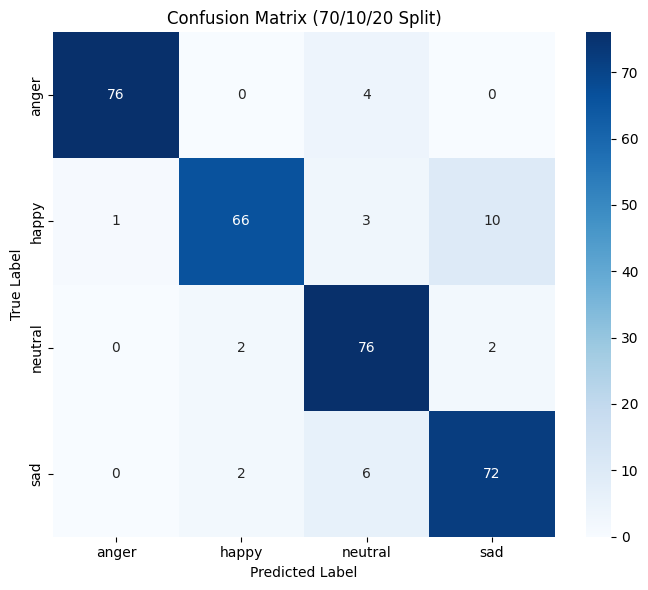

In [ ]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7,6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=emotions,
    yticklabels=emotions
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix (70/10/20 Split)")
plt.tight_layout()
plt.show()